# Examen Final del Curso de Python — Pandas y NumPy
**Alumna:** Vannia 
**Carrera:** Ingeniería de los papois 

**Dataset:** `living.csv` — costo de vida por país (2017).  
Columnas: `Countries`, `Cost of living, 2017`, `Global rank`, `Available data` y `Continent`.

## 0. Carga del dataset

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# index_col=0 evita que la primera columna (solo un índice 0, 1, 2...) cuente como dato
df = pd.read_csv("living.csv", index_col=0)
COL = "Cost of living, 2017"

os.makedirs("images", exist_ok=True)
print(df.head())
print()
df.info()

     Countries  Cost of living, 2017  Global rank Available data Continent
0      Bermuda                225.86            1    2017 - 2017   America
1      Iceland                209.10            2    2017 - 2017    Europe
2  Switzerland                197.89            3    2017 - 2017    Europe
3       Norway                186.52            4    2017 - 2017    Europe
4      Denmark                171.78            5    2017 - 2017    Europe

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Countries             167 non-null    str    
 1   Cost of living, 2017  167 non-null    float64
 2   Global rank           167 non-null    int64  
 3   Available data        167 non-null    str    
 4   Continent             167 non-null    str    
dtypes: float64(1), int64(1), str(3)
memory usage: 6.7 KB


## 1. Revisión inicial del dataset
Se responde la **Tabla para el Ejercicio 1**.

In [2]:
filas, columnas = df.shape

costo_promedio = np.mean(df[COL])                      # NumPy
pais_mas_alto = df.loc[df[COL].idxmax(), "Countries"]  # Pandas
pais_mas_bajo = df.loc[df[COL].idxmin(), "Countries"]

peru = df[df["Countries"] == "Peru"].iloc[0]

tabla = pd.DataFrame({
    "Campo": [
        "Nro. de Filas",
        "Nro. de Columnas",
        "Costo de vida promedio",
        "País con costo de vida más alto",
        "País con costo de vida más bajo",
        "Costo de Vida en Perú",
        "Ranking de Perú",
    ],
    "Respuesta": [
        filas,
        columnas,
        round(costo_promedio, 2),
        f"{pais_mas_alto} ({df[COL].max()})",
        f"{pais_mas_bajo} ({df[COL].min()})",
        peru[COL],
        f"{peru['Global rank']} de {filas}",
    ],
})
print(tabla.to_string(index=False))

                          Campo        Respuesta
                  Nro. de Filas              167
               Nro. de Columnas                5
         Costo de vida promedio            82.92
País con costo de vida más alto Bermuda (225.86)
País con costo de vida más bajo    Egypt (27.37)
          Costo de Vida en Perú            83.26
                Ranking de Perú        60 de 167


**Nota:** el archivo CSV trae una primera columna sin nombre que solo es un índice (0, 1, 2...). Al leerlo con `index_col=0` se descarta, y quedan **5 columnas con datos reales**.

## 2. Visualizaciones

### 2.1 Los 10 países con el costo de vida más alto

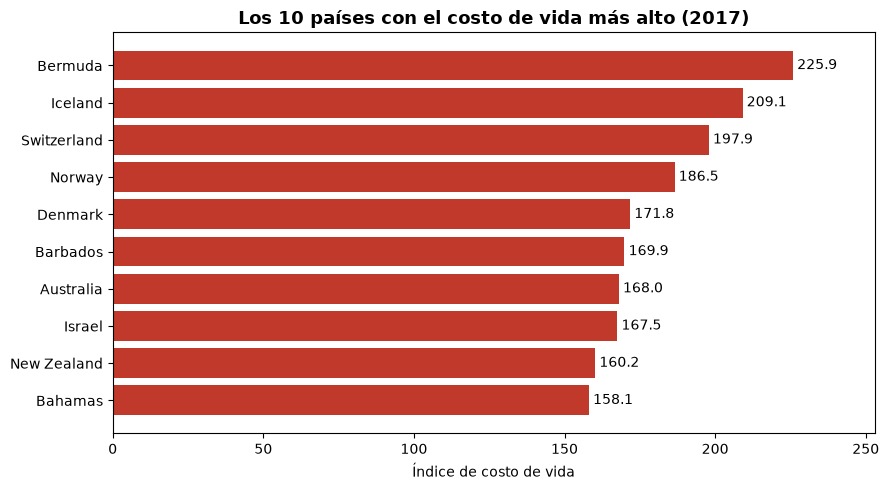

In [3]:
top10 = df.nlargest(10, COL).sort_values(COL)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(top10["Countries"], top10[COL], color="#c0392b")
ax.bar_label(barras, fmt="%.1f", padding=3)
ax.set_title("Los 10 países con el costo de vida más alto (2017)", fontsize=13, fontweight="bold")
ax.set_xlabel("Índice de costo de vida")
ax.set_xlim(0, top10[COL].max() * 1.12)
plt.tight_layout()
plt.savefig("images/top10_mas_alto.png", dpi=150)
plt.show()

### 2.2 Los 10 países con el costo de vida más bajo

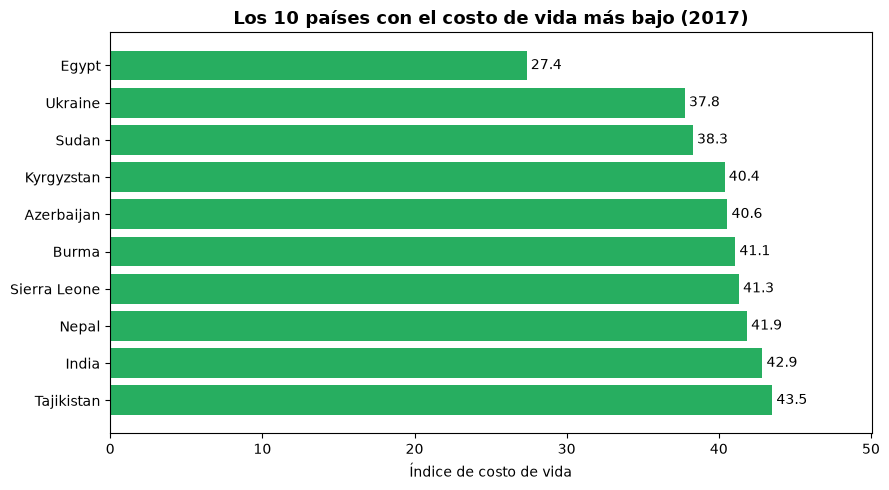

In [4]:
bottom10 = df.nsmallest(10, COL).sort_values(COL, ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(bottom10["Countries"], bottom10[COL], color="#27ae60")
ax.bar_label(barras, fmt="%.1f", padding=3)
ax.set_title("Los 10 países con el costo de vida más bajo (2017)", fontsize=13, fontweight="bold")
ax.set_xlabel("Índice de costo de vida")
ax.set_xlim(0, bottom10[COL].max() * 1.15)
plt.tight_layout()
plt.savefig("images/top10_mas_bajo.png", dpi=150)
plt.show()

### 2.3 El costo de vida de los países de América

Países de América en el dataset: 32


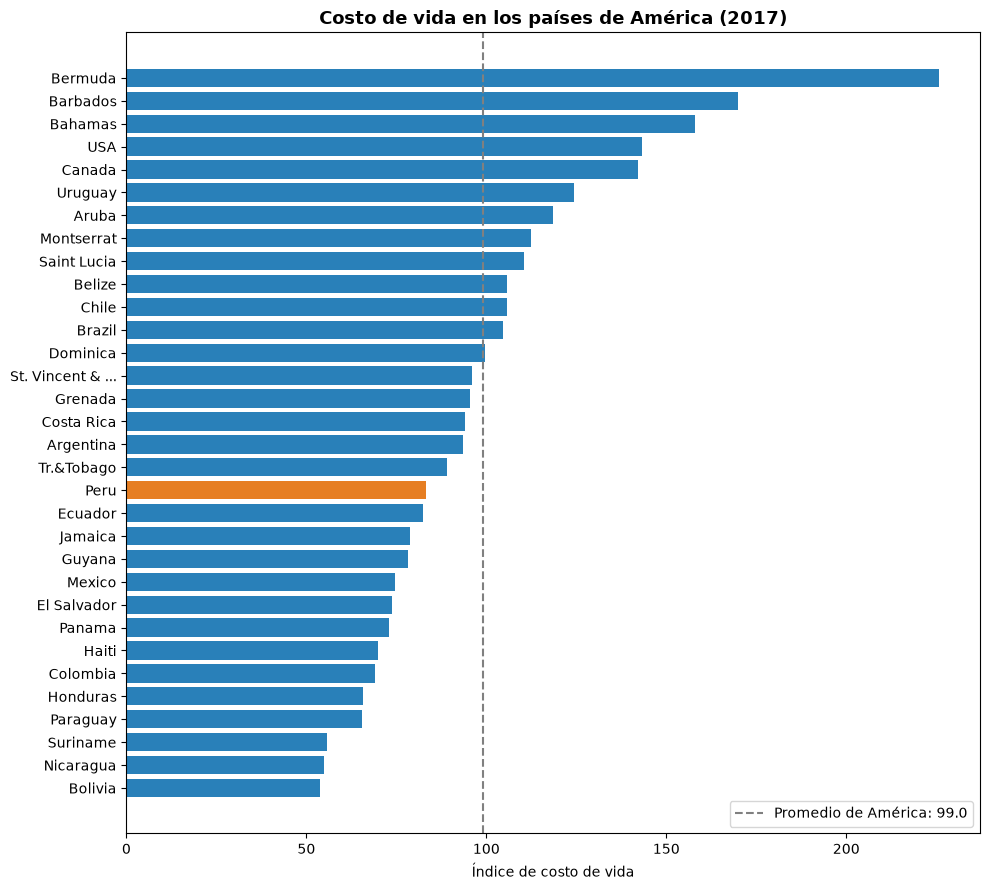

In [5]:
america = df[df["Continent"] == "America"].sort_values(COL, ascending=False)
print("Países de América en el dataset:", len(america))

# Perú resaltado en otro color
colores = ["#e67e22" if p == "Peru" else "#2980b9" for p in america["Countries"]]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(america["Countries"], america[COL], color=colores)
ax.invert_yaxis()   # el más caro arriba
ax.set_title("Costo de vida en los países de América (2017)", fontsize=13, fontweight="bold")
ax.set_xlabel("Índice de costo de vida")
ax.axvline(america[COL].mean(), color="gray", linestyle="--", label=f"Promedio de América: {america[COL].mean():.1f}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/costo_vida_america.png", dpi=150)
plt.show()

## 3. Conclusiones
- **Bermuda** tiene el costo de vida más alto del dataset (225.86) y **Egipto** el más bajo (27.37).
- **Perú** (puesto 60 de 167, índice 83.26) está prácticamente en el promedio mundial (82.92).
- En **América** el promedio es ≈ 99; Perú queda por debajo de él (puesto 19 de 32 países del continente).
- Dentro de América hay mucha diferencia: de Bermuda (225.86) a Bolivia (53.79).